# PRIM Baseline Exploration — 500 LHS runs

Find parameter boxes where:
1. T1 BCAS mortality exceeds a threshold
2. T2 NATO timeline compliance drops below a threshold

In [4]:
import sys
from pathlib import Path
_root = Path(".").resolve()
while not (_root / "paths.py").exists():
    _root = _root.parent
sys.path.insert(0, str(_root))
import paths

import pandas as pd
import numpy as np
from ema_workbench.analysis import prim

# ── CONFIGURATION ────────────────────────────────────────────────────────────
FOLDER_NAME = "20260604_195538_scenario_2btg_1ccp_each"
T1_MORTALITY_THRESHOLD = 0.0    # mortality > this value is "interesting"
T2_TIMELINE_THRESHOLD  = 0.9    # fraction < this value is "interesting"
# ─────────────────────────────────────────────────────────────────────────────

df = pd.read_csv(paths.MULTI_RUN_OUTPUT / FOLDER_NAME / "results.csv")
print(f"Loaded {len(df)} runs")
print(f"T1 mortality range: {df['death_rate_T1_BCAS'].min():.4f} – {df['death_rate_T1_BCAS'].max():.4f}")
print(f"T2 timeline range:  {df['frac_t2_within_timeline'].min():.4f} – {df['frac_t2_within_timeline'].max():.4f}")

# Uncertainty columns used in the experiment
UNCERTAINTIES = [c for c in ["ccp_r1_same_bn_min", "bcas_rate", "waves_per_day", "wave_duration_min"] if c in df.columns]
x = df[UNCERTAINTIES].astype(float)
print(f"Uncertainties: {UNCERTAINTIES}")

Loaded 2000 runs
T1 mortality range: 0.0000 – 1.0000
T2 timeline range:  0.0000 – 1.0000
Uncertainties: ['ccp_r1_same_bn_min', 'bcas_rate', 'waves_per_day', 'wave_duration_min']


## 1. PRIM — T1 BCAS Mortality

Cases of interest: 1685 / 2000 (84.2%)

Selected box (click on tradeoff plot to change):
coverage      0.199407
density       0.988235
id           23.000000
k           336.000000
mass          0.170000
mean          0.988235
n           340.000000
res_dim       4.000000
Name: 23, dtype: float64

                       box 23                               
                          min        max  qp value  qp value
waves_per_day        1.000000   3.500000       NaN  0.003293
bcas_rate            0.029231   0.079874  0.000070       NaN
ccp_r1_same_bn_min  14.500000  30.000000  0.004455       NaN
wave_duration_min    2.000000  90.000000  0.628839  0.113560


[None]

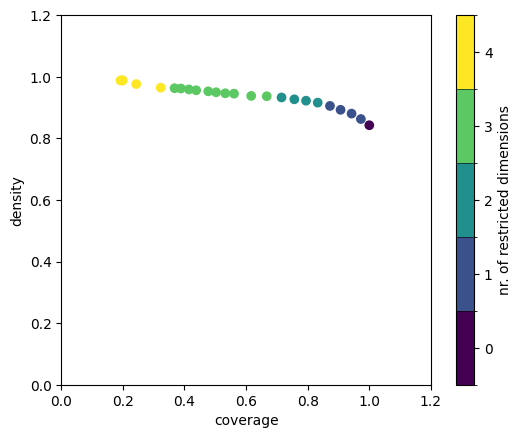

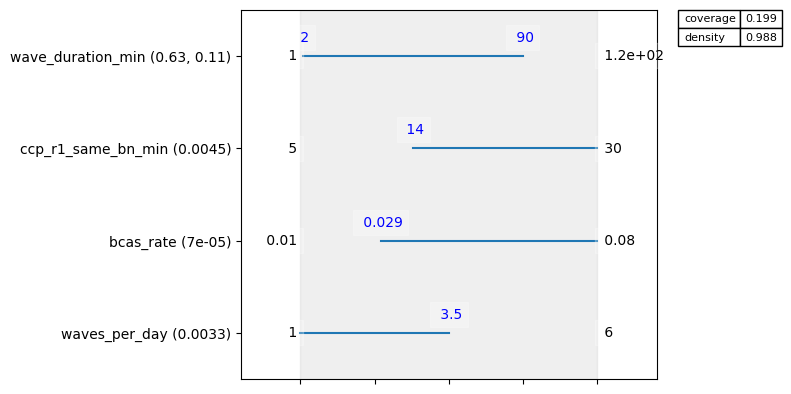

In [7]:
y_t1 = df["death_rate_T1_BCAS"].values > T1_MORTALITY_THRESHOLD
print(f"Cases of interest: {y_t1.sum()} / {len(y_t1)} ({y_t1.mean():.1%})")

p_t1 = prim.Prim(x, y_t1, threshold=0.5)
box_t1 = p_t1.find_box()
box_t1.show_tradeoff()
print("\nSelected box (click on tradeoff plot to change):")
box_t1.inspect(style="graph")
box_t1.inspect()

## 2. PRIM — T2 NATO Timeline Compliance

Cases of interest: 1872 / 2000 (93.6%)

Selected box (click on tradeoff plot to change):
coverage      0.520833
density       0.998975
id           14.000000
k           975.000000
mass          0.488000
mean          0.998975
n           976.000000
res_dim       3.000000
Name: 14, dtype: float64

                       box 14                                    
                          min         max      qp value  qp value
wave_duration_min    1.000000  108.500000           NaN  0.002904
bcas_rate            0.028451    0.079874  2.175231e-12       NaN
ccp_r1_same_bn_min  11.500000   30.000000  2.728378e-03       NaN


[None]

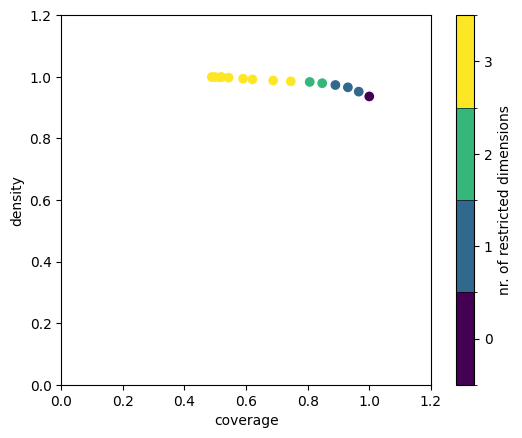

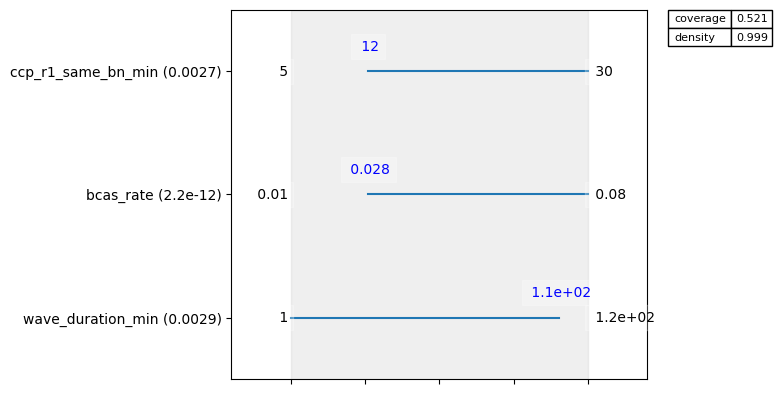

In [8]:
y_t2 = df["frac_t2_within_timeline"].values < T2_TIMELINE_THRESHOLD
print(f"Cases of interest: {y_t2.sum()} / {len(y_t2)} ({y_t2.mean():.1%})")

p_t2 = prim.Prim(x, y_t2, threshold=0.5)
box_t2 = p_t2.find_box()
box_t2.show_tradeoff()
print("\nSelected box (click on tradeoff plot to change):")
box_t2.inspect(style="graph")
box_t2.inspect()